<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# Preserve a join without treating redaction as an identifier

A redacted email is convenient to display, but several people can have the same display value. A deterministic token can preserve equality across tables when both sides use the same input and key. We compare those joins, reconcile their row counts and amounts, and then change the orders’ key version.

**Every customer, address and order is invented.** Addresses use `example.test`; all amounts are synthetic USD cents. The keys named `public-demo-key-v1` and `public-demo-key-v2` are deliberately public test strings, not secrets. This notebook is a join-correctness demonstration, not a recipe for storing production keys in SQL or a claim of anonymization. Deterministic tokens reveal equality and frequency; redaction still reveals parts of the original value.

## One key-version experiment

`ORDER_KEY_VERSION` accepts **"v1"** or **"v2"**, default **"v1"**. Orders use the selected version. We compare a customer mapping generated with that same version, a customer mapping fixed at v1, and a deliberately incorrect join on redacted display text. Restart and run all after editing.

In [1]:
ORDER_KEY_VERSION = "v1"  # public demonstration key version; not a secret

In [2]:
import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator, StrMethodFormatter

from notebook_support import finish, theme

assert ORDER_KEY_VERSION in {"v1", "v2"}
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-mask/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-mask/notebooks/pyproject.toml.

## Keep an explicit synthetic reference

Customers have unique exact email strings. Orders include one missing email and one address absent from the customer table. Those rows remain unmatched; missing data is not an identity of its own. We do not lowercase, trim or otherwise normalize identifiers in this example. A production pipeline needs a consistent identity/normalization contract before tokenization.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'mask' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-mask@v0.4.0');
CREATE TABLE customers AS
SELECT * FROM (VALUES
 ('C01','alice@example.test','North'),('C02','amber@example.test','South'),
 ('C03','bruno@example.test','North'),('C04','blake@example.test','West'),
 ('C05','carol@example.test','West'),('C06','diana@example.test','South')
) AS t(customer_id,email,region);
CREATE TABLE orders AS
SELECT * FROM (VALUES
 ('O01','alice@example.test',12000),('O02','alice@example.test',8000),
 ('O03','amber@example.test',4000),('O04','bruno@example.test',6500),
 ('O05','blake@example.test',1500),('O06','carol@example.test',9000),
 ('O07','diana@example.test',5000),('O08','amber@example.test',6000),
 ('O09','bruno@example.test',3500),('O10',NULL,2500),('O11','guest@example.test',7000)
) AS t(order_id,email,amount_cents);
CREATE TABLE reference AS
SELECT o.order_id,c.customer_id,c.region,o.amount_cents
FROM orders o JOIN customers c ON o.email=c.email;

,Count


In [4]:
%%sql inventory <<
SELECT count(*) AS source_orders,sum(amount_cents)/100.0 AS source_usd,
 count(*) FILTER(WHERE email IS NULL) AS missing_email_orders,
 count(*) FILTER(WHERE email IS NOT NULL AND email NOT IN(SELECT email FROM customers)) AS unknown_email_orders,
 (SELECT count(*) FROM customers) AS customers,
 (SELECT count(*) FROM reference) AS reference_matched_orders,
 (SELECT sum(amount_cents)/100.0 FROM reference) AS reference_matched_usd
FROM orders;

In [5]:
display(inventory)
r = inventory.iloc[0]
display(
    Markdown(
        f"The reference joins **{int(r.reference_matched_orders)} of {int(r.source_orders)} orders**, "
        f"worth USD **{r.reference_matched_usd:,.2f}**. "
        f"Missing-email orders: **{int(r.missing_email_orders)}**; "
        f"unknown-email orders: **{int(r.unknown_email_orders)}**. "
        "These availability limits should remain visible after tokenization."
    )
)

,source_orders,source_usd,missing_email_orders,unknown_email_orders,customers,reference_matched_orders,reference_matched_usd
0,11,650.0,1,1,6,9,555.0


The reference joins **9 of 11 orders**, worth USD **555.00**. Missing-email orders: **1**; unknown-email orders: **1**. These availability limits should remain visible after tokenization.

## Create separate join keys and display values

Every token and redaction below is returned by the real worker. Materializing each extract keeps later charts and joins local. Full **32-character token strings** are used for equality; display labels are never promoted to unique keys. Customer IDs are synthetic audit labels, not anonymized identifiers.

The full plaintext fixture remains visible for this educational comparison. A protected extract would need an access and key-management design; this notebook does not create one.

In [6]:
%%sql
CREATE TABLE customer_extract AS
SELECT customer_id,region,
 mask.main.mask_token(email,'public-demo-key-{{ORDER_KEY_VERSION}}') AS aligned_token,
 mask.main.mask_token(email,'public-demo-key-v1') AS fixed_v1_token,
 mask.main.mask_redact(email,'email') AS email_display
FROM customers;
CREATE TABLE order_extract AS
SELECT order_id,amount_cents,
 mask.main.mask_token(email,'public-demo-key-{{ORDER_KEY_VERSION}}') AS customer_token,
 mask.main.mask_redact(email,'email') AS email_display
FROM orders;

,Count


In [7]:
%%sql mapping <<
SELECT customer_id,region,email_display,aligned_token,fixed_v1_token,
 count(*) OVER(PARTITION BY email_display) AS customers_sharing_display
FROM customer_extract ORDER BY customer_id;

In [8]:
display(mapping)
colliding = int((mapping.customers_sharing_display > 1).sum())
changed = int((mapping.aligned_token != mapping.fixed_v1_token).sum())
display(
    Markdown(
        f"Customers whose display value is shared: **{colliding} of {len(mapping)}**. "
        f"Tokens different from the fixed v1 mapping: **{changed} of {len(mapping)}**. "
        "Repeated display strings explain why redaction can expand a join. "
        "Observed token uniqueness in this small fixture is a check, not a proof that collisions are impossible."
    )
)

,customer_id,region,email_display,aligned_token,fixed_v1_token,customers_sharing_display
0,C01,North,a****@example.test,6ae7aad0bfdfdac0eb19375401b8244c,6ae7aad0bfdfdac0eb19375401b8244c,2
1,C02,South,a****@example.test,41a8a750a4569ea727bf34c84193aaa5,41a8a750a4569ea727bf34c84193aaa5,2
2,C03,North,b****@example.test,dd1b520f4b156172e98372032fc0fdad,dd1b520f4b156172e98372032fc0fdad,2
3,C04,West,b****@example.test,fc7fa0385da223a8cb9926d7e118850e,fc7fa0385da223a8cb9926d7e118850e,2
4,C05,West,c****@example.test,40ed426b2ff97349dfbb586a2171bd78,40ed426b2ff97349dfbb586a2171bd78,1
5,C06,South,d****@example.test,06444a325dbe1535d7005872ea93517f,06444a325dbe1535d7005872ea93517f,1


Customers whose display value is shared: **4 of 6**. Tokens different from the fixed v1 mapping: **0 of 6**. Repeated display strings explain why redaction can expand a join. Observed token uniqueness in this small fixture is a check, not a proof that collisions are impossible.

## Compare matched orders with joined rows

For each strategy, count distinct matched order IDs separately from result rows. A one-to-many join can inflate both row counts and sums while leaving the matched-order count unchanged. The redacted join below is an intentional counterexample. The fixed-v1 strategy exposes a version mismatch when orders switch to v2.

In [9]:
%%sql
CREATE TABLE strategies AS SELECT * FROM (VALUES
 (1,'Aligned tokens'),(2,'Fixed v1 customer tokens'),(3,'Redacted display values')
) AS t(position,strategy);
CREATE TABLE joined AS
SELECT 'Aligned tokens' AS strategy,o.order_id,c.customer_id,c.region,o.amount_cents
FROM order_extract o JOIN customer_extract c ON o.customer_token=c.aligned_token
UNION ALL
SELECT 'Fixed v1 customer tokens',o.order_id,c.customer_id,c.region,o.amount_cents
FROM order_extract o JOIN customer_extract c ON o.customer_token=c.fixed_v1_token
UNION ALL
SELECT 'Redacted display values',o.order_id,c.customer_id,c.region,o.amount_cents
FROM order_extract o JOIN customer_extract c ON o.email_display=c.email_display;
CREATE TABLE outcomes AS
SELECT s.position,s.strategy,count(j.order_id) AS joined_rows,
 count(DISTINCT j.order_id) AS matched_orders,
 (SELECT count(*) FROM orders)-count(DISTINCT j.order_id) AS unmatched_orders,
 count(j.order_id)-count(DISTINCT j.order_id) AS extra_join_rows,
 coalesce(sum(j.amount_cents),0) AS joined_cents
FROM strategies s LEFT JOIN joined j USING(strategy) GROUP BY s.position,s.strategy;

,Count


In [10]:
%%sql comparisons <<
SELECT strategy,joined_rows,matched_orders,unmatched_orders,extra_join_rows,
 joined_cents/100.0 AS joined_usd
FROM outcomes ORDER BY position;

,strategy,joined_rows,matched_orders,unmatched_orders,extra_join_rows,joined_usd
0,Aligned tokens,9,9,2,0,555.0
1,Fixed v1 customer tokens,9,9,2,0,555.0
2,Redacted display values,16,9,2,7,970.0


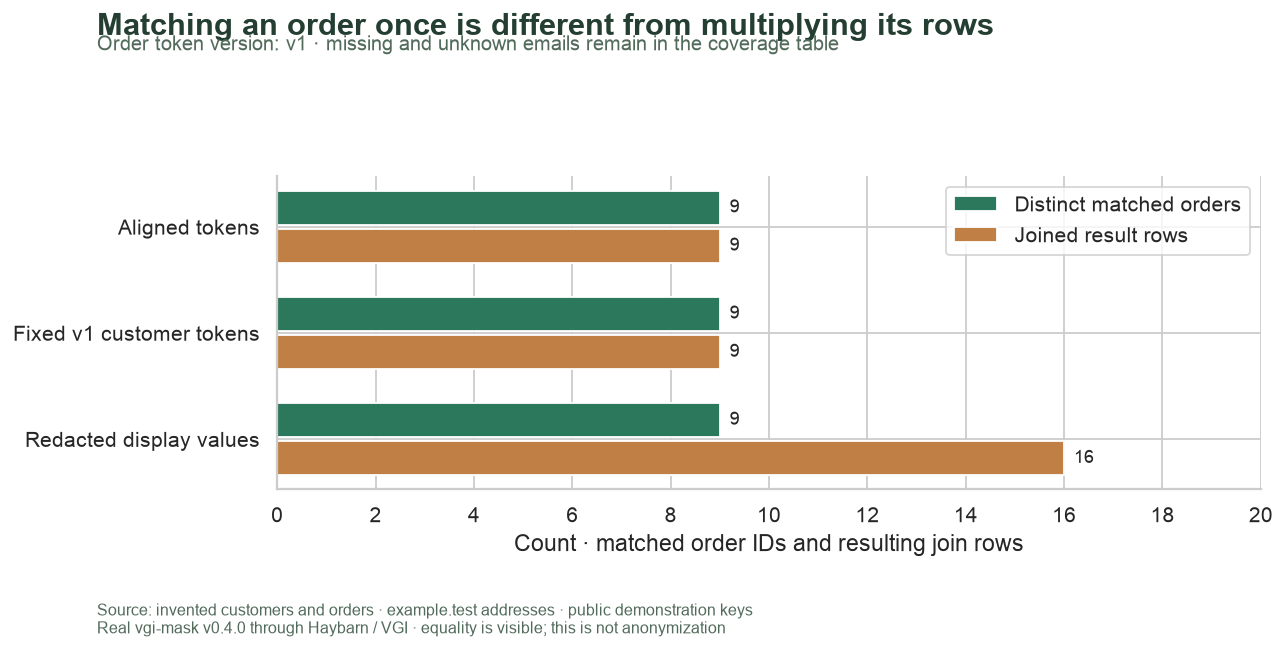

In [11]:
display(comparisons)
y = list(range(len(comparisons)))
fig, ax = plt.subplots(figsize=(10.5, 5))
for offset, column, color, label in [
    (-0.18, "matched_orders", "#2c785d", "Distinct matched orders"),
    (0.18, "joined_rows", "#c08045", "Joined result rows"),
]:
    bars = ax.barh([i + offset for i in y], comparisons[column], height=0.32, color=color, label=label)
    for bar in bars:
        ax.text(
            bar.get_width() + 0.2,
            bar.get_y() + bar.get_height() / 2,
            str(int(bar.get_width())),
            va="center",
            fontsize=10,
        )
ax.set_yticks(y, comparisons.strategy)
ax.invert_yaxis()
ax.set_xlim(0, max(float(comparisons.joined_rows.max()), float(comparisons.matched_orders.max())) + 4)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Count · matched order IDs and resulting join rows")
ax.legend(loc="upper right", frameon=True)
finish(
    fig,
    f"join-counts-{ORDER_KEY_VERSION}",
    "Matching an order once is different from multiplying its rows",
    f"Order token version: {ORDER_KEY_VERSION} · missing and unknown emails remain in the coverage table",
)

## Reconcile joined amounts to the reference

Amounts are summed as integer USD cents before conversion. The dashed reference is the exact-email join on this synthetic source, not the full source total. A zero matched sum means **no matching rows** under that strategy; it does not mean those source orders had zero value.

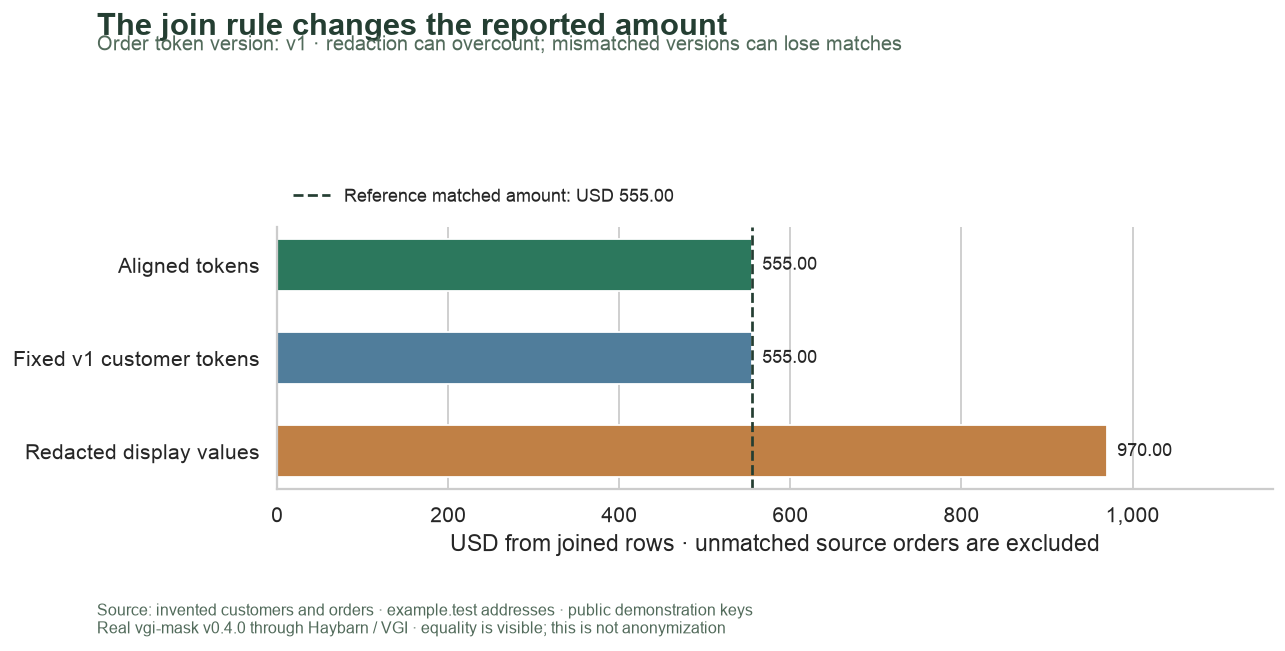

In [12]:
fig, ax = plt.subplots(figsize=(10.5, 5))
colors = ["#2c785d", "#507d9b", "#c08045"]
bars = ax.barh(comparisons.strategy, comparisons.joined_usd, color=colors, height=0.56)
for bar, row in zip(bars, comparisons.itertuples(), strict=True):
    label = f"{bar.get_width():,.2f}" if row.joined_rows else "No matched rows"
    ax.text(bar.get_width() + 12, bar.get_y() + bar.get_height() / 2, label, va="center", fontsize=10)
reference_usd = float(inventory.iloc[0].reference_matched_usd)
ax.axvline(
    reference_usd,
    color="#243e32",
    linestyle="--",
    linewidth=1.5,
    label=f"Reference matched amount: USD {reference_usd:,.2f}",
)
ax.invert_yaxis()
ax.set_xlim(0, max(float(comparisons.joined_usd.max()), reference_usd) * 1.2)
ax.set_xlabel("USD from joined rows · unmatched source orders are excluded")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), frameon=False, fontsize=10)
finish(
    fig,
    f"joined-amounts-{ORDER_KEY_VERSION}",
    "The join rule changes the reported amount",
    f"Order token version: {ORDER_KEY_VERSION} · redaction can overcount; mismatched versions can lose matches",
)

In [13]:
aligned = comparisons.iloc[0]
fixed = comparisons.iloc[1]
redacted = comparisons.iloc[2]
display(
    Markdown(
        f"Aligned tokens retain **{int(aligned.matched_orders)} matched orders** "
        f"and USD **{aligned.joined_usd:,.2f}**, "
        f"agreeing with the reference. The display-value join adds **{int(redacted.extra_join_rows)} extra rows** "
        f"and USD **{redacted.joined_usd - aligned.joined_usd:,.2f}**. "
        f"With order version **{ORDER_KEY_VERSION}**, "
        f"the fixed-v1 mapping matches **{int(fixed.matched_orders)} orders**; "
        f"its unmatched count is **{int(fixed.unmatched_orders)}**. "
        "Changing a key is a coordinated data migration: both sides need a compatible version before joining."
    )
)

Aligned tokens retain **9 matched orders** and USD **555.00**, agreeing with the reference. The display-value join adds **7 extra rows** and USD **415.00**. With order version **v1**, the fixed-v1 mapping matches **9 orders**; its unmatched count is **2**. Changing a key is a coordinated data migration: both sides need a compatible version before joining.

## Check relational invariants

Verify that the aligned join preserves the reference pairs and amount, no token collisions occur in the supplied customer sample, NULL remains NULL, and matched/unmatched accounting is complete. We also reconcile every strategy’s joined sum against its source-order multiplicity. Passing these checks does not certify privacy, production key handling or global token uniqueness.

In [14]:
%%sql checks <<
SELECT 'source customer emails are unique and present' AS check_name,
 count(*)=count(DISTINCT email) AND count(email)=count(*) AS passed FROM customers
UNION ALL SELECT 'source order IDs unique',count(*)=count(DISTINCT order_id) FROM orders
UNION ALL SELECT 'amounts are nonnegative integer cents',bool_and(amount_cents IS NOT NULL AND amount_cents>=0 AND typeof(amount_cents)='INTEGER') FROM orders
UNION ALL SELECT 'customer token format complete',bool_and(regexp_full_match(aligned_token,'[0-9a-f]{32}') AND regexp_full_match(fixed_v1_token,'[0-9a-f]{32}')) FROM customer_extract
UNION ALL SELECT 'no token collisions in this customer fixture',count(*)=count(DISTINCT aligned_token) FROM customer_extract
UNION ALL SELECT 'same inputs under aligned key produce the same token',bool_and(o.customer_token=c.aligned_token)
 FROM reference r JOIN order_extract o USING(order_id) JOIN customer_extract c USING(customer_id)
UNION ALL SELECT 'missing source email remains NULL',bool_and(e.customer_token IS NULL AND e.email_display IS NULL)
 FROM orders o JOIN order_extract e USING(order_id) WHERE o.email IS NULL
UNION ALL SELECT 'aligned join has exactly the reference pairs',
 (SELECT count(*) FROM (SELECT order_id,customer_id FROM joined WHERE strategy='Aligned tokens' EXCEPT SELECT order_id,customer_id FROM reference))=0 AND
 (SELECT count(*) FROM (SELECT order_id,customer_id FROM reference EXCEPT SELECT order_id,customer_id FROM joined WHERE strategy='Aligned tokens'))=0
UNION ALL SELECT 'aligned join does not multiply orders',count(*)=count(DISTINCT order_id) FROM joined WHERE strategy='Aligned tokens'
UNION ALL SELECT 'aligned amount equals source reference',sum(amount_cents)=(SELECT sum(amount_cents) FROM reference) FROM joined WHERE strategy='Aligned tokens'
UNION ALL SELECT 'coverage accounts for every source order',bool_and(matched_orders+unmatched_orders=(SELECT count(*) FROM orders)) FROM outcomes
UNION ALL SELECT 'row multiplication is explicit',bool_and(joined_rows=matched_orders+extra_join_rows AND extra_join_rows>=0) FROM outcomes
UNION ALL SELECT 'strategy sums equal source amount times multiplicity',bool_and(o.joined_cents=coalesce(x.recomputed_cents,0))
 FROM outcomes o LEFT JOIN (
 SELECT j.strategy,sum(s.amount_cents) AS recomputed_cents FROM joined j JOIN orders s USING(order_id) GROUP BY j.strategy
 ) x USING(strategy);

In [15]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
display(
    Markdown(
        f"All **{len(checks)} relational checks** pass. "
        "The corrected join preserves accounting; it does not remove "
        "the equality/frequency information that deterministic tokens expose."
    )
)

,check_name,passed
0,source customer emails are unique and present,True
1,source order IDs unique,True
2,amounts are nonnegative integer cents,True
3,customer token format complete,True
4,no token collisions in this customer fixture,True
5,same inputs under aligned key produce the same...,True
6,missing source email remains NULL,True
7,aligned join has exactly the reference pairs,True
8,aligned join does not multiply orders,True
9,aligned amount equals source reference,True


All **13 relational checks** pass. The corrected join preserves accounting; it does not remove the equality/frequency information that deterministic tokens expose.

## Try one change

Change `ORDER_KEY_VERSION` from **"v1"** to **"v2"**, restart and run all. Predict which customer tokens and joined totals change. The aligned-token result must still match the plaintext reference, while the fixed-v1 strategy reveals the incomplete migration. Redacted strings and their join inflation stay unchanged because redaction takes no key. Restore **"v1"** for the saved default. This is a deliberately small fixture, not a key-rotation implementation.

In [16]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>